In [ ]:
# Libraries
import sys
from google.colab import drive

shared_path = '/content/drive/Shareddrives/OSOM_Project/Packages'

import site
site.addsitedir(shared_path)

# sys.path.insert(0, '/content/drive/Shareddrives/OSOM_Project/Packages')
import netCDF4
import numpy as np
import requests as req
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import csv
import pandas as pd

# Buoy

### Data Collection

Mounted at /content/drive


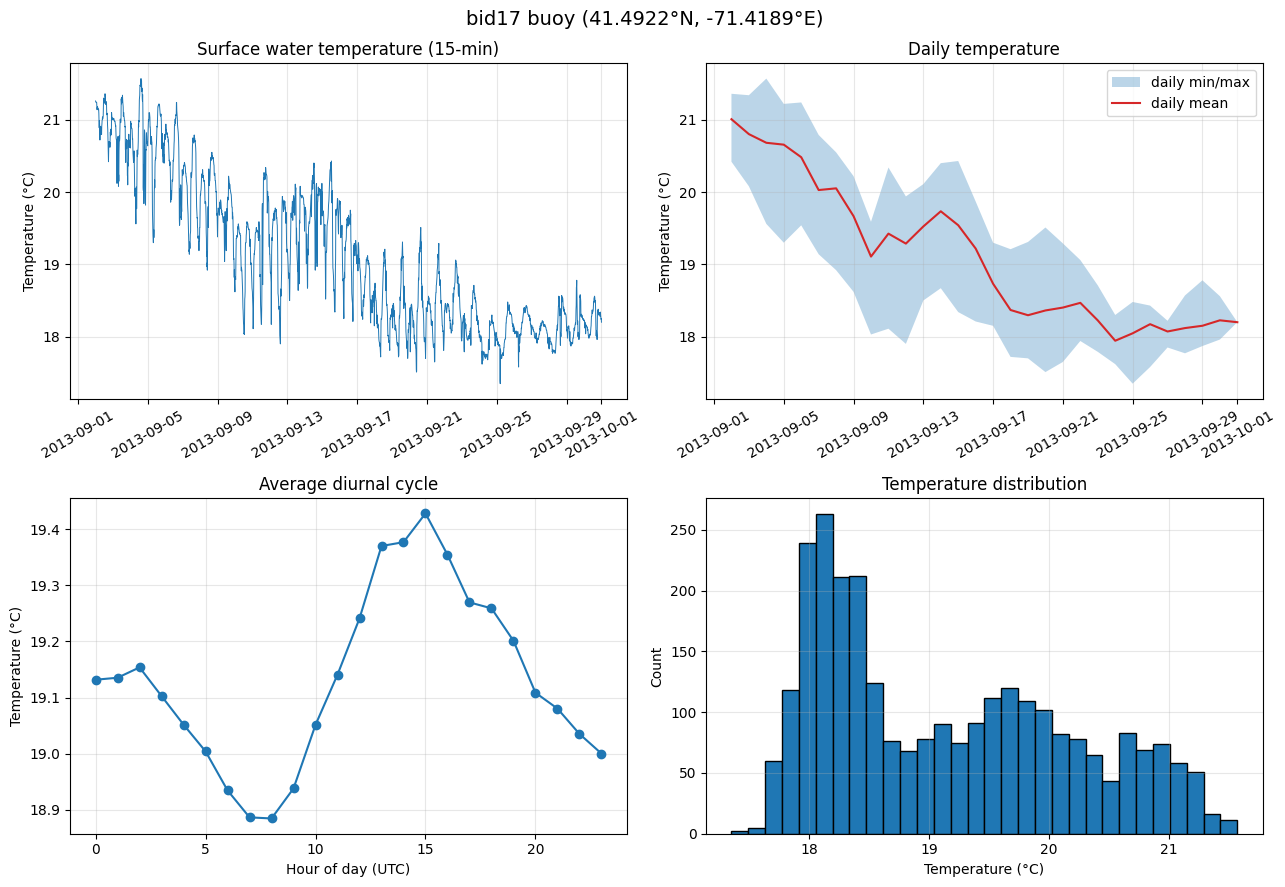

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount = True)

fpath = '/content/drive/Shareddrives/OSOM_Project/Buoy/bid17_2013_sept_oct.csv'

df = pd.read_csv(fpath, skiprows=[1])
df['time'] = pd.to_datetime(df['time'])
df = df.set_index('time')
temp = df['WaterTempSurface']

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Full 15-minute time series
axes[0, 0].plot(temp.index, temp, lw=0.7)
axes[0, 0].set_title('Surface water temperature (15-min)')
axes[0, 0].set_ylabel('Temperature (°C)')

# 2. Daily mean with min/max band
daily = temp.resample('D').agg(['mean', 'min', 'max'])
axes[0, 1].fill_between(daily.index, daily['min'], daily['max'], alpha=0.3, label='daily min/max')
axes[0, 1].plot(daily.index, daily['mean'], color='C3', label='daily mean')
axes[0, 1].set_title('Daily temperature')
axes[0, 1].set_ylabel('Temperature (°C)')
axes[0, 1].legend()

# 3. Diurnal cycle: average temp by hour of day (UTC)
hourly = temp.groupby(temp.index.hour).mean()
axes[1, 0].plot(hourly.index, hourly.values, marker='o')
axes[1, 0].set_title('Average diurnal cycle')
axes[1, 0].set_xlabel('Hour of day (UTC)')
axes[1, 0].set_ylabel('Temperature (°C)')

# 4. Distribution
axes[1, 1].hist(temp, bins=30, edgecolor='k')
axes[1, 1].set_title('Temperature distribution')
axes[1, 1].set_xlabel('Temperature (°C)')
axes[1, 1].set_ylabel('Count')

for ax in axes.flat:
    ax.grid(alpha=0.3)
for ax in axes[0]:
    ax.tick_params(axis='x', rotation=30)

fig.suptitle(f"bid17 buoy ({df['latitude'].iloc[0]}°N, {df['longitude'].iloc[0]}°E)", fontsize=14)
plt.tight_layout()
plt.savefig('bid17_plots.png', dpi=150)
plt.show()

# Landsat

### Requesting Data

using the following URL:
https://erddap.riddc.brown.edu/erddap/griddap/landsat_sst_narrbay_v3_data.nc

In [ ]:
url = (
    "https://erddap.riddc.brown.edu/erddap/griddap/"
    "landsat_sst_narrbay_v3_data"
)

landsat_dt = xr.open_dataset(url, engine="netcdf4")
landsat_grid = xr.open_dataset("/content/drive/Shareddrives/OSOM_Project/Landsat/landsat_sst_narrbay_v4_grid.nc")


In [ ]:
# date of interests:
date_of_interest = np.array([2013, 5])
length_of_time = np.array([0,5])
date_start = "2013-09-01"
date_end = "2013-10-01"

In [ ]:
# Assign coordinates
ls_cr = landsat_dt.assign_coords(lat=landsat_grid["Latitude"], lon=landsat_grid["Longitude"])

# Select the Dates
sample_ls = ls_cr.sel(
    time=slice(date_start, date_end)
)

sample_ls

In [ ]:
# mask the nonphysical values
mask = (sample_ls["temperature"] >= 0) & (sample_ls["temperature"] <= 25)

may_masked_temp = sample_ls["temperature"].where(mask)

Note that in order to find the closest grid to the target buoy where the intended comparison will be made, we need to apply the *haversine* formula to find the distance between two points based on their **lat & lon**.
The *haversine* formula is written as the following:
$d = r\theta$, Where r is radius of Earth and $\theta$ can be determined by,
\begin{equation}
\theta  = 2\sin^{-1}\left(\text{hav}\, \theta\right) \\
\text{hav} \,\theta = \frac{1-\cos(\Delta\phi)+\cos(\phi_1)\cdot\cos(\phi_2)\cdot(1-\cos(\Delta\lambda)}{2}
\end{equation}
Where $\phi$ stands for latitude and $\lambda$ stands for longitude.

In [ ]:
# locate the nearest grid to bid17 bouy
target_lat = 41.4922
target_lon =  -71.4189

lat = np.deg2rad(landsat_grid["Latitude"])
lon = np.deg2rad(landsat_grid["Longitude"])

lat0 = np.deg2rad(target_lat)
lon0 = np.deg2rad(target_lon)

# haversine function
hav_t = (1-np.cos(lat - lat0) + np.cos(lat)*np.cos(lat0)*(1-np.cos(lon-lon0)))/2
# radius of earth in km
R = 6371
# distance while ensuring calculation is correct
d =  2 * R * np.arcsin(np.sqrt(hav_t.clip(0, 1)))

iy, ix = np.unravel_index(
    np.nanargmin(d.values),
    d.shape
)

## Plotting Graphs

# Model

In [ ]:
may_masked_temp.isel(time=1).plot(x="lon", y="lat")

In [ ]:
point_temperature = may_masked_temp.isel(Y=iy, X=ix)
point_temperature
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(point_temperature['time'].values, point_temperature.values)
ax.set_title("Landsat Corrected SST Measurement at grid closest to bid17 from 2012")
ax.set_ylabel("Sea Surface Temperature (°C)")
ax.set_xlabel("Date")

## Query

In [ ]:
# Query related variables
date_of_interest = np.array([2013, 9]) # [year, month]. day=1 by default
length_of_time = np.array([0, 1]) # 1 month
buoy_id = "bid17"

## Data Request

Using the following to obtain data:

https://erddap.riddc.brown.edu/erddap/tabledap/osom_v2_0585_f867_db94.html

In [ ]:
def date_list_to_date_str(date:list) -> str:
    if date[1] > 12:
        date[0] += 1
        date[1] = date[1] % 12

    if date[1] < 1:
        date[0] -= 1
        date[1] = (date[1] - 1) % 13

    if date[1] < 10:
        date_str = str(date[0]) + "-" + "0" + str(date[1]) + "-" + "01"
    elif 10 <= date[1]:
        date_str = str(date[0]) + "-" + str(date[1]) + "-" + "01"
    else:
        raise("Invalid month")

    return date_str

# Test
print(date_list_to_date_str(np.array([2012, 6])))
print(date_list_to_date_str(np.array([2012, 12]) + np.array([0, 1])))
print(date_list_to_date_str(np.array([2012, 1]) - np.array([0, 1])))

In [ ]:
# Obtain model data
datasetID = "osom_v2_0585_f867_db94"
file_type = ".nc"
variables = "SalinityBottom%2CSalinitySurface%2CWaterTempBottom%2CWaterTempSurface%2CSurfaceHeight%2CVelocityEastwardBottom%2CVelocityEastwardSurface%2CVelocityNorthwardBottom%2CVelocityNorthwardSurface%2CKineticEnergyBottom%2CKineticEnergySurface%2Ctime%2Cstation_name%2Clatitude%2Clongitude"

date_start = date_list_to_date_str(date_of_interest)
date_end = date_list_to_date_str(date_of_interest + length_of_time)

time_start_query = "time%3E=" + date_start + "T00%3A00%3A00Z"
time_end_query = "time%3C=" + date_end + "T00%3A00%3A00Z"
station_name_query = "station_name=" + "%22" + buoy_id + "%22"

query_list = [time_start_query, time_end_query, station_name_query]

queries = "&" + "&".join(query_list)

form_request = "https://erddap.riddc.brown.edu/erddap/tabledap/" + datasetID + file_type + "?" + variables + queries

response = req.get(form_request)
response.raise_for_status()
data = response.content

model_data = xr.open_dataset(data)

# Uncomment to check available variables
# print(model_data)

## Plot Graphs

In [ ]:
# Surface Height
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(model_data["time"].values, model_data["SurfaceHeight"].values)

ax.set_title("OSOM model data of water surface height at " + buoy_id + " starting " + date_list_to_date_str(date_of_interest))
ax.set_xlabel("date (m-d)")
ax.set_ylabel("Water Surface Height (m)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
ax.grid(True)

In [ ]:
# Surface Temperature
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(model_data["time"].values, model_data["WaterTempSurface"].values)

ax.set_title("OSOM model data of water surface temperature at " + buoy_id + " starting " + date_list_to_date_str(date_of_interest))
ax.set_xlabel("date (m-d)")
ax.set_ylabel("Water surface temperature (°C)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
ax.grid(True)

# Comparison

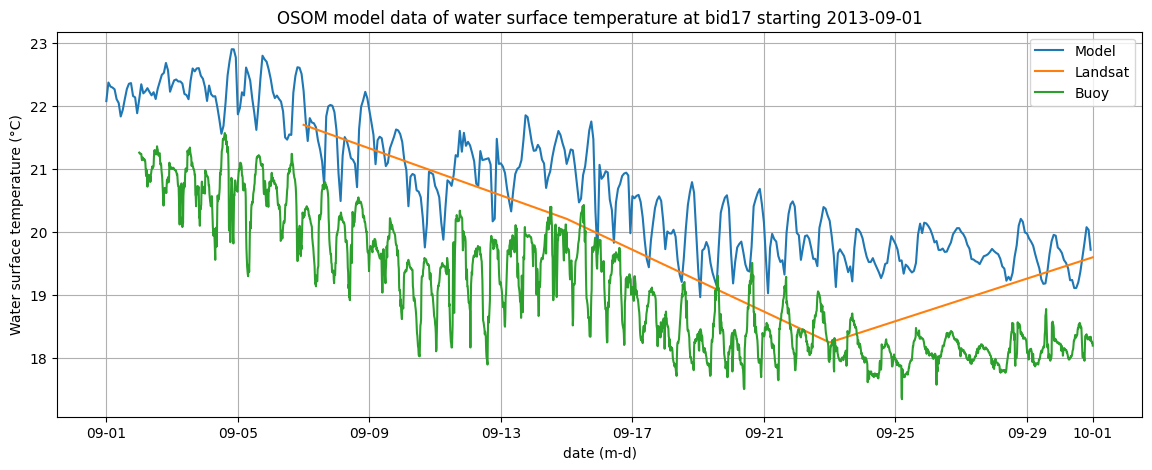

In [ ]:
# Buoy
buoy_dt = temp.index
buoy_sst = temp

# Landsat
landsat_dt = point_temperature['time'].values,
landsat_sst = point_temperature.values

# Model
model_dt = model_data["time"].values
model_sst = model_data["WaterTempSurface"].values

# Surface Temperature
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(model_dt, model_sst, label="Model")
ax.plot(point_temperature['time'].values, point_temperature.values, label="Landsat")
ax.plot(buoy_dt, buoy_sst, label="Buoy")

ax.legend()

ax.set_title("OSOM model data of water surface temperature at " + buoy_id + " starting " + date_list_to_date_str(date_of_interest))
ax.set_xlabel("date (m-d)")
ax.set_ylabel("Water surface temperature (°C)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
ax.grid(True)